<a href="https://colab.research.google.com/github/find143/suraj__24/blob/main/task5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Customer Segmentation using K-Means and DBSCAN

## Project Overview
This project aims to segment retail customers based on their demographic characteristics and spending behaviors using unsupervised learning algorithms: **K-Means Clustering** and **DBSCAN**.

### Objective
- Explore and visualize the distribution of customer features (Age, Annual Income, Spending Score).
- Standardize the features for optimal clustering performance.
- Use **K-Means Clustering** and determine the optimal number of clusters using the **Elbow Method** and **Silhouette Analysis**.
- Implement **DBSCAN** as an alternative density-based clustering model.
- Provide a comprehensive analysis and profiling of each segmented customer group.

In [10]:
# Step 1: Install and Download Dataset using kagglehub
!pip install kagglehub pandas matplotlib seaborn scikit-learn -q

import kagglehub
import os

# Download latest version of Mall Customer Segmentation dataset
path = kagglehub.dataset_download("vjchoudhary7/customer-segmentation-tutorial-in-python")
print("Path to dataset files:", path)

# Locate the CSV file inside the downloaded path
csv_files = [f for f in os.listdir(path) if f.endswith('.csv')]
if csv_files:
    csv_path = os.path.join(path, csv_files[0])
    print(f"Found CSV file: {csv_path}")
else:
    print("No CSV file found.")

Using Colab cache for faster access to the 'customer-segmentation-tutorial-in-python' dataset.
Path to dataset files: /kaggle/input/customer-segmentation-tutorial-in-python
Found CSV file: /kaggle/input/customer-segmentation-tutorial-in-python/Mall_Customers.csv


In [11]:
# Step 2: Load the Dataset and Initial Exploration
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Load data
df = pd.read_csv(csv_path)

# Rename columns for cleaner coding and visualization
df.rename(columns={
    'Genre': 'Gender',
    'Annual Income (k$)': 'Annual_Income',
    'Spending Score (1-100)': 'Spending_Score'
}, inplace=True)

print("--- Data Preview ---")
display(df.head())

print("\n--- Dataset Info ---")
print(df.info())

print("\n--- Summary Statistics ---")
display(df.describe())

--- Data Preview ---


,CustomerID,Gender,Age,Annual_Income,Spending_Score
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40



--- Dataset Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   CustomerID      200 non-null    int64 
 1   Gender          200 non-null    object
 2   Age             200 non-null    int64 
 3   Annual_Income   200 non-null    int64 
 4   Spending_Score  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB
None

--- Summary Statistics ---


,CustomerID,Age,Annual_Income,Spending_Score
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


## Exploratory Data Analysis (EDA)

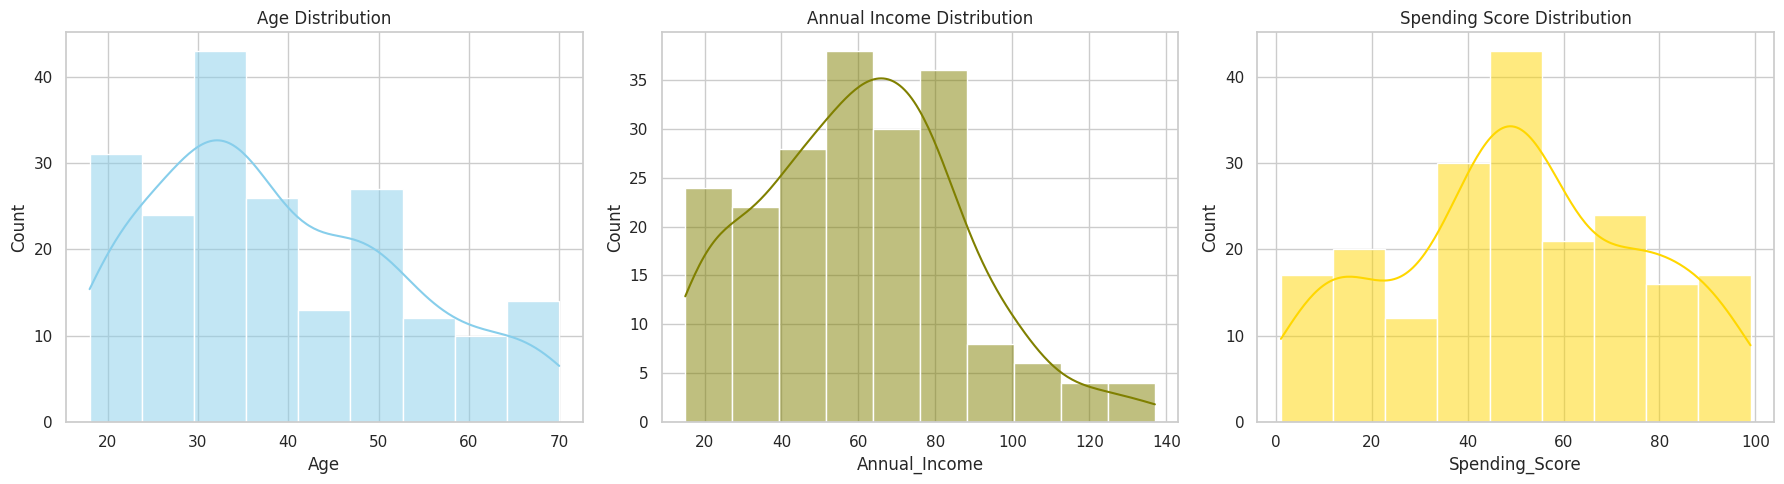

In [12]:
# Visualize distributions and correlations
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(df['Age'], kde=True, ax=axes[0], color='skyblue').set_title('Age Distribution')
sns.histplot(df['Annual_Income'], kde=True, ax=axes[1], color='olive').set_title('Annual Income Distribution')
sns.histplot(df['Spending_Score'], kde=True, ax=axes[2], color='gold').set_title('Spending Score Distribution')

plt.tight_layout()
plt.show()

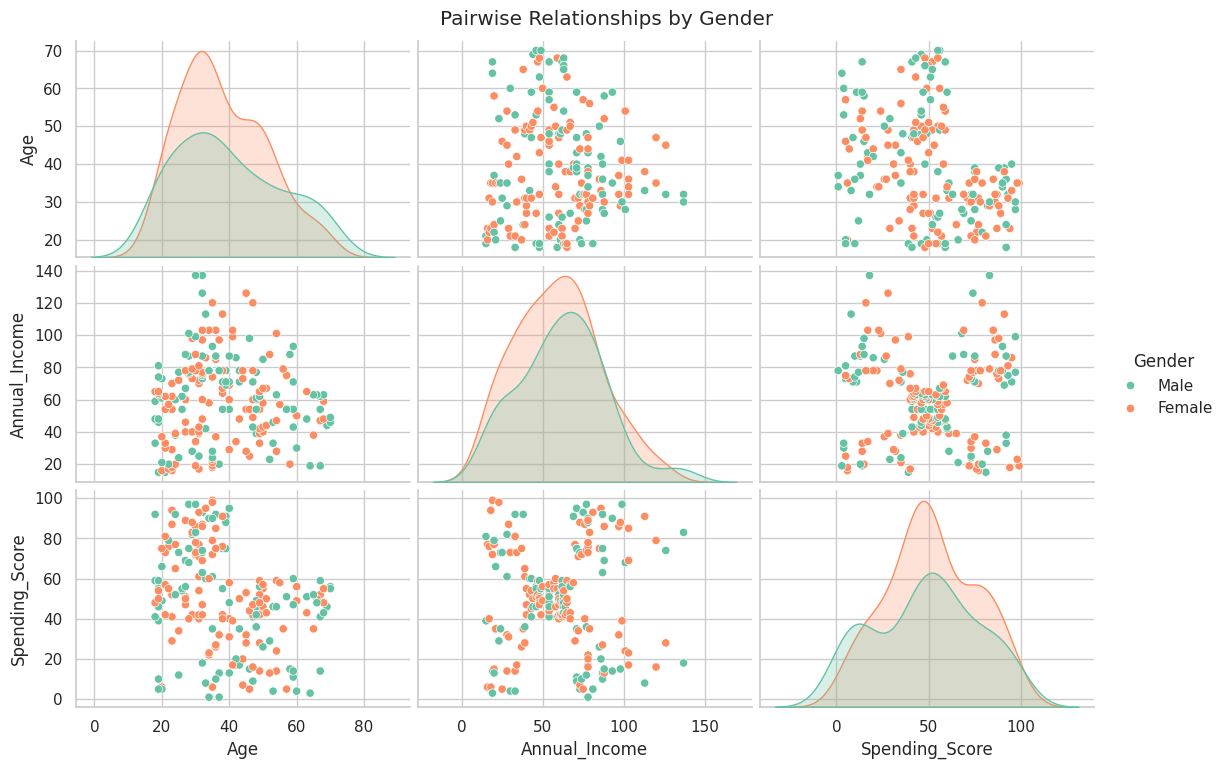

In [13]:
# Pairplot to explore relationships between variables grouped by Gender
sns.pairplot(df.drop(columns=['CustomerID']), hue='Gender', palette='Set2', aspect=1.5)
plt.suptitle('Pairwise Relationships by Gender', y=1.02)
plt.show()

## Data Preprocessing and Feature Scaling

In [14]:
from sklearn.preprocessing import StandardScaler

# We will segment based on the two key variables: Annual Income and Spending Score
X = df[['Annual_Income', 'Spending_Score']].values

# Scale features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("First 5 scaled features:")
print(X_scaled[:5])

First 5 scaled features:
[[-1.73899919 -0.43480148]
 [-1.73899919  1.19570407]
 [-1.70082976 -1.71591298]
 [-1.70082976  1.04041783]
 [-1.66266033 -0.39597992]]


## K-Means Clustering
We will find the optimal number of clusters using both the **Within-Cluster Sum of Squares (WCSS)** (Elbow Method) and **Silhouette Scores**.

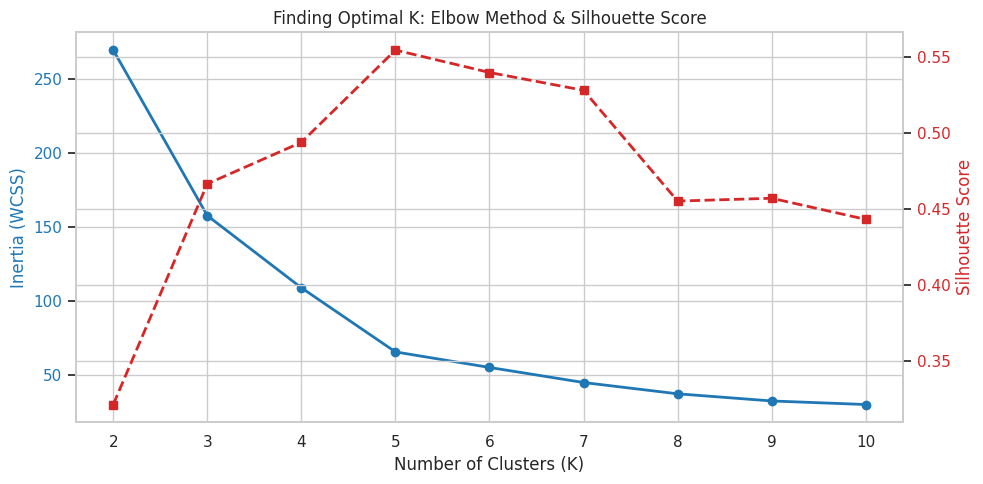

In [15]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

wcss = []
silhouette_scores = []
K_range = range(2, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(X_scaled, kmeans.labels_))

# Plotting the Elbow Method and Silhouette Scores side-by-side
fig, ax1 = plt.subplots(figsize=(10, 5))

color = 'tab:blue'
ax1.set_xlabel('Number of Clusters (K)')
ax1.set_ylabel('Inertia (WCSS)', color=color)
ax1.plot(K_range, wcss, marker='o', color=color, linewidth=2)
ax1.tick_params(axis='y', labelcolor=color)
ax1.set_title('Finding Optimal K: Elbow Method & Silhouette Score')

ax2 = ax1.twinx()
color = 'tab:red'
ax2.set_ylabel('Silhouette Score', color=color)
ax2.plot(K_range, silhouette_scores, marker='s', color=color, linewidth=2, linestyle='--')
ax2.tick_params(axis='y', labelcolor=color)

plt.tight_layout()
plt.show()

Based on the graphs, the Elbow curve points to a clear change in rate of decrease at **K=5**, which also yields the highest **Silhouette Score**. Let's fit our final K-Means model with **5 clusters**.

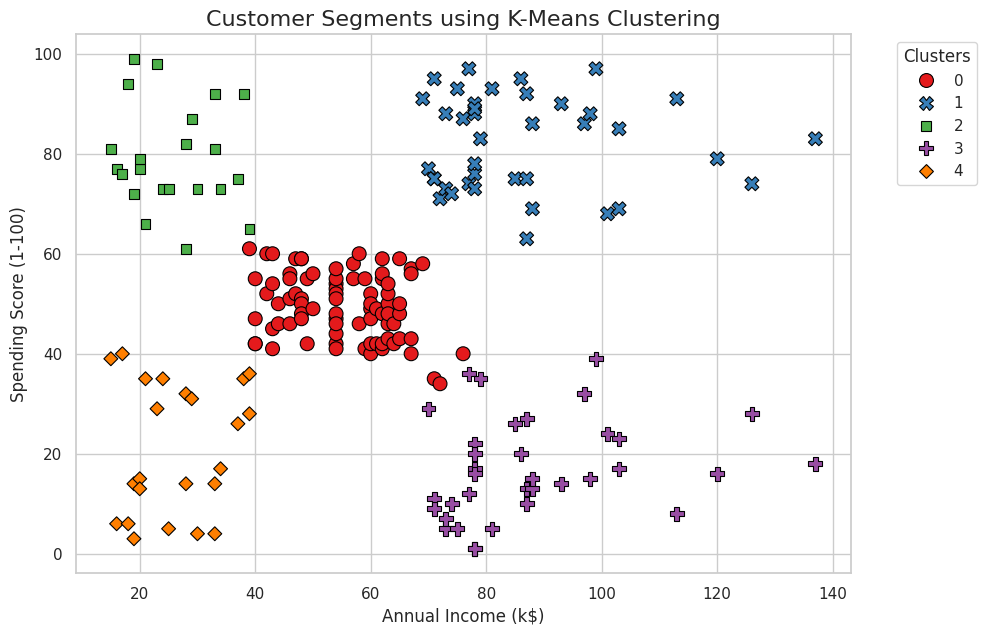

In [16]:
# Train and fit K-Means with optimal K=5
optimal_k = 5
kmeans = KMeans(n_clusters=optimal_k, init='k-means++', random_state=42, n_init=10)
df['KMeans_Cluster'] = kmeans.fit_predict(X_scaled)

# Visualizing Clusters in 2D
plt.figure(figsize=(10, 7))
sns.scatterplot(
    x=df['Annual_Income'],
    y=df['Spending_Score'],
    hue=df['KMeans_Cluster'],
    palette='Set1',
    s=100,
    edgecolor='black',
    style=df['KMeans_Cluster']
)

plt.title('Customer Segments using K-Means Clustering', fontsize=16)
plt.xlabel('Annual Income (k$)', fontsize=12)
plt.ylabel('Spending Score (1-100)', fontsize=12)
plt.legend(title='Clusters', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()

## Advanced Clustering: DBSCAN (Bonus)

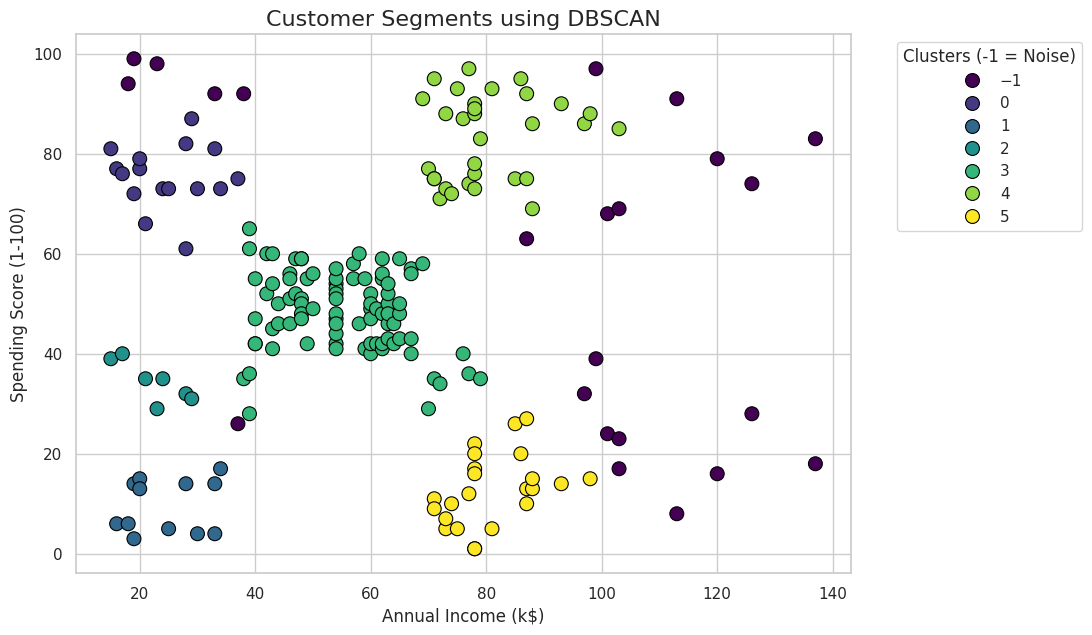

In [17]:
from sklearn.cluster import DBSCAN

# Let's try DBSCAN (Density-Based Spatial Clustering of Applications with Noise)
dbscan = DBSCAN(eps=0.35, min_samples=5)
df['DBSCAN_Cluster'] = dbscan.fit_predict(X_scaled)

# Plotting DBSCAN results (Label -1 indicates Outliers/Noise)
plt.figure(figsize=(10, 7))
sns.scatterplot(
    x=df['Annual_Income'],
    y=df['Spending_Score'],
    hue=df['DBSCAN_Cluster'],
    palette='viridis',
    s=100,
    edgecolor='black'
)

plt.title('Customer Segments using DBSCAN', fontsize=16)
plt.xlabel('Annual Income (k$)', fontsize=12)
plt.ylabel('Spending Score (1-100)', fontsize=12)
plt.legend(title='Clusters (-1 = Noise)', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()

## Cluster Analysis & Profiling (K-Means)

In [18]:
# Calculate average traits per K-Means cluster
cluster_summary = df.groupby('KMeans_Cluster').agg({
    'Age': 'mean',
    'Annual_Income': 'mean',
    'Spending_Score': 'mean',
    'CustomerID': 'count'
}).rename(columns={'CustomerID': 'Count'}).reset_index()

display(cluster_summary)

,KMeans_Cluster,Age,Annual_Income,Spending_Score,Count
0,0,42.716049,55.296296,49.518519,81
1,1,32.692308,86.538462,82.128205,39
2,2,25.272727,25.727273,79.363636,22
3,3,41.114286,88.200000,17.114286,35
4,4,45.217391,26.304348,20.913043,23


### Customer Personas Defined:
- **Cluster 0**: High Income, Low Spending (Careful Customers)
- **Cluster 1**: Moderate Income, Moderate Spending (Average/Standard Customers)
- **Cluster 2**: High Income, High Spending (Target/Premium Customers)
- **Cluster 3**: Low Income, High Spending (Careless/Impulsive Customers)
- **Cluster 4**: Low Income, Low Spending (Sensible/Frugal Customers)